In [4]:
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder

rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

In [ ]:
model = 'deepseek'
model = 'llama'

n_files = 10
batch_size = 10 
Ns = batch_size*n_files
II_folder = makefolder(base=f'./results/',
                               create_folder=True,
                               model=model,
                               n_files=n_files,
                               )
n_tokens_list = [10]
for n_tokens in n_tokens_list:
  IIs = np.load(II_folder + f'n_tokens_{n_tokens}_AB.npy')

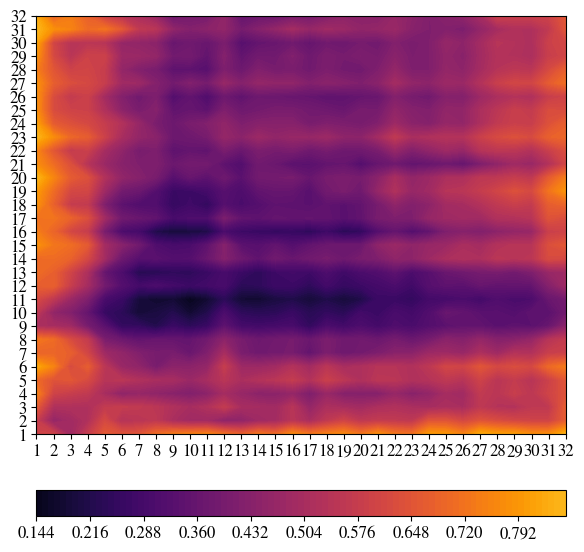

In [ ]:
languageA = 'english'
languageB = 'spanish'

figsfolder = makefolder(base=f'./results/figs/')

cmap = 'inferno'
levels = 100
vmin = 0.1
vmax = 1 

# vmin = np.min(IIs)
# vmax = np.max(IIs)
# levels = np.linspace(0.1, 1.001, 101)

if model == 'llama':
  B_layer_ids = np.arange(1,32+1)
  A_layer_ids = np.arange(1,32+1)


fig,ax = plt.subplots(1,1,
                      figsize=(6,6),
                      # constrained_layout=True,
                      )
im0 = ax.contourf(B_layer_ids,A_layer_ids,IIs[:, :], levels=levels, vmin=vmin, vmax=vmax, cmap=cmap)

ax.set_xticks(ticks=A_layer_ids, labels=A_layer_ids)
ax.set_yticks(ticks=B_layer_ids, labels=B_layer_ids)
ax.set_xlabel(f'layer {languageA}')
ax.set_ylabel(f'layer {languageB}')
ax.set_title(r'$\Delta$' + f' {languageA} --> {languageB}')

cbar0 = fig.colorbar(im0, ax=ax, 
                      orientation='horizontal', 
                      pad=0.1)  # Adjust pad as needed

fig.suptitle(f'{model} - {model} ; T: {n_tokens} ; ' r'$N_s=$' f'{Ns}')
fig.tight_layout()
# fig.subplots_adjust(bottom=0.)
plt.show()
fig.savefig(f'{figfolder}Ntokens{Ntokens_A}_Nbits{Nbits}_Ns_{Ns}.pdf',bbox_inches='tight')